---
title: "Tesseract vs. EasyOCR — From Quick Wins to Robust Pipelines"
author: "Fabian"
date: "2025-08-21"
categories: ["Machine Learning"]
image: thumbnail.png
format:
  html:
    code-fold: false
    toc: true
    echo: true
jupyter: python3
freeze: true

---

> I wrote this post because I had to re-learn OCR recently. I kept forgetting the details, configs, and gotchas — so this is my reference to stay sharp. If you’re in the same boat, copy this into a Jupyter notebook or run the code cells as-is.



## TL;DR

- **Use Tesseract** when you can preprocess your images into clean, high-contrast, deskewed text blocks. It’s fast, accurate, and transparent.
- **Use EasyOCR** when layout is messy, images are low-quality, or you need a **one-function** solution that handles a lot of cases out-of-the-box.
- The real secret: **good preprocessing** beats model choice more often than not. Below, I show a **minimal example** and then a **full, production-style preprocessing pipeline** you can reuse.

## What we’ll build

1. A **minimal OCR demo** using both libraries on a synthetic image (so the notebook always runs without external assets).
2. A **robust preprocessing pipeline** (OpenCV) that handles skew, noise, line removal, and multi-block pages — then feeds the cleaned image into Tesseract and EasyOCR for comparison.
3. A tiny **evaluation helper** so you can sanity-check your results vs. expected text.


## Why I’m writing this

I needed OCR again recently and realized I’d forgotten a bunch of the practical bits:
- Which `--psm` to use in Tesseract?
- What’s the fastest path to “good enough” when the scan is crooked or low DPI?
- When should I reach for EasyOCR instead?
This post is my “drop-in” reference — with code I can paste right into a Jupyter notebook.


## Setup & prerequisites

> **Note:** Tesseract requires the native binary **in addition** to the Python wrapper `pytesseract`.

### Install (macOS / Linux / Windows)

**macOS (Homebrew):**
```bash
brew install tesseract 
pip install pytesseract easyocr opencv-python-headless pillow numpy matplotlib
```

**Ubuntu / Debian:**
```bash
sudo apt-get update && sudo apt-get install -y tesseract-ocr
pip install pytesseract easyocr opencv-python-headless pillow numpy matplotlib
```

**Windows:**
1. Install Tesseract from the official Windows installer (add to PATH during setup).
2. Then:
```bash
pip install pytesseract easyocr opencv-python pillow numpy matplotlib
```

In [1]:
import pytesseract, sys, os, platform
print("Python:", sys.version)
print("Platform:", platform.platform())
print("pytesseract:", pytesseract.__version__)

Python: 3.12.2 | packaged by conda-forge | (main, Feb 16 2024, 20:54:21) [Clang 16.0.6 ]
Platform: macOS-15.5-arm64-arm-64bit
pytesseract: 0.3.13


## Quick differences (practical viewpoint)

- **Tesseract** shines with **clean prints** and when you can control preprocessing. You can tweak `--psm` (page segmentation) and `--oem` (engine mode) for accuracy and speed.
- **EasyOCR** is great for **messy images** and **quick starts**: it does detection + recognition in one shot and is more forgiving without heavy preprocessing.
- If you need the most control and explainability (data pipelines that you can reason about), **start with Tesseract + OpenCV**. If you want a fast “good enough,” try **EasyOCR** first.

### Minimal `--psm` cheat sheet (Tesseract)

- `--psm 6`: Assume a single uniform block of text (good for paragraphs).
- `--psm 11`: Sparse text (no particular order) — useful for screenshots / scattered text.
- `--psm 3`: Fully automatic page segmentation (no OSD) — general default when unsure.


## Part 1 — Minimal example (synthetic image)

We’ll generate a synthetic text image (so this notebook is self-contained), then run **Tesseract** and **EasyOCR** on it.


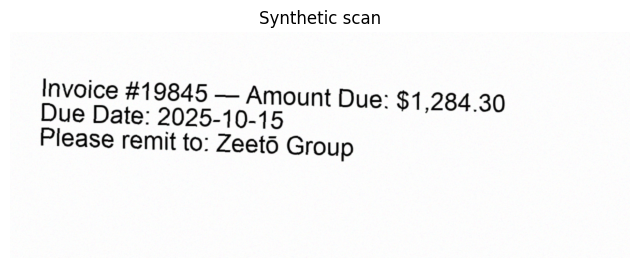

In [2]:
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pytesseract

# --- Generate a synthetic image with text ---
W, H = 1200, 400
img = Image.new("RGB", (W, H), "white")
draw = ImageDraw.Draw(img)

# Try to grab a font; fall back if not available.
def get_font(size=48):
    # These paths are heuristic; adjust to your system if needed.
    candidates = [
        "/System/Library/Fonts/Supplemental/Arial.ttf",
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "C:/Windows/Fonts/arial.ttf",
    ]
    for p in candidates:
        try:
            return ImageFont.truetype(p, size=size)
        except Exception:
            pass
    return ImageFont.load_default()

font = get_font(48)
text = "Invoice #19845 — Amount Due: $1,284.30\nDue Date: 2025-10-15\nPlease remit to: Zeetō Group"
draw.text((50, 80), text, font=font, fill=(0,0,0))

# Add mild rotation and noise to simulate a scan
img = img.rotate(-2, expand=True, fillcolor="white")
noisy = np.array(img).astype(np.uint8)
noise = np.random.normal(0, 6, noisy.shape).astype(np.int16)
noisy = np.clip(noisy.astype(np.int16) + noise, 0, 255).astype(np.uint8)
noisy_img = Image.fromarray(noisy).filter(ImageFilter.GaussianBlur(0.6))

plt.figure(figsize=(8,3))
plt.imshow(noisy_img); plt.axis('off'); plt.title('Synthetic scan')
plt.show()

In [3]:
# --- Minimal Tesseract ---
gray = cv2.cvtColor(np.array(noisy_img), cv2.COLOR_RGB2GRAY)
tess_config = "--oem 3 --psm 6 -l eng"
tess_text = pytesseract.image_to_string(gray, config=tess_config)
print("Tesseract says:\n", tess_text)


Tesseract says:
 Invoice #19845 — Amount Due: $1,284.30
Due Date: 2025-10-15
Please remit to: Zeeto Group



In [4]:
# --- Minimal EasyOCR ---
import easyocr
reader = easyocr.Reader(['en'], gpu=False)  # set gpu=True if CUDA available
results = reader.readtext(np.array(noisy_img))
easy_text = "\n".join([r[1] for r in results])
print("\nEasyOCR says:\n", easy_text)

Using CPU. Note: This module is much faster with a GPU.



EasyOCR says:
 Invoice #19845
Amount Due: $1,284.30
Due Date: 2025-10-15
Please remit to: Zeeto
Group


> You should already get decent results. If not, jump to the pipeline below — it will almost always help.


## Part 2 — A robust preprocessing pipeline (OpenCV)

Real documents are messy: skewed, low DPI, scans with lines and stamps, or multi-column layouts. Below is a compact pipeline you can adapt anywhere.

### Pipeline overview

1. **Grayscale → CLAHE** (local contrast boost)
2. **Denoise** (Gaussian / bilateral)
3. **Threshold** (adaptive for uneven lighting)
4. **Deskew** (compute angle from text regions)
5. **Line removal** (horizontal/vertical morphology)
6. **(Optional) Block segmentation** (contours / bounding boxes)
7. **OCR with tuned configs**

In [5]:
import numpy as np
import cv2
from typing import Tuple, List

def to_gray(img):
    if img.ndim == 3:
        return cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return img

def clahe(gray, clip=3.0, tile=(8,8)):
    c = cv2.createCLAHE(clipLimit=clip, tileGridSize=tile)
    return c.apply(gray)

def denoise(gray, ksize=3):
    return cv2.GaussianBlur(gray, (ksize, ksize), 0)

def adaptive_binarize(gray, block=31, C=10):
    return cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, block, C)

def deskew(binary):
    # Invert: text as 1s
    inv = 255 - binary
    coords = np.column_stack(np.where(inv > 0))
    if coords.size == 0:
        return binary, 0.0
    rect = cv2.minAreaRect(coords)
    angle = rect[-1]
    if angle < -45:
        angle = 90 + angle
    # Rotate
    (h, w) = binary.shape[:2]
    M = cv2.getRotationMatrix2D((w//2, h//2), angle, 1.0)
    rotated = cv2.warpAffine(binary, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
    return rotated, angle

def remove_lines(binary, scale=40):
    # Remove horizontal and vertical lines
    horiz = binary.copy()
    vert = binary.copy()
    cols = horiz.shape[1]
    h_size = max(1, cols // scale)
    h_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (h_size, 1))
    horiz = cv2.erode(horiz, h_kernel, iterations=1)
    horiz = cv2.dilate(horiz, h_kernel, iterations=1)

    rows = vert.shape[0]
    v_size = max(1, rows // scale)
    v_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1, v_size))
    vert = cv2.erode(vert, v_kernel, iterations=1)
    vert = cv2.dilate(vert, v_kernel, iterations=1)

    mask = cv2.bitwise_or(horiz, vert)
    cleaned = cv2.bitwise_and(binary, cv2.bitwise_not(mask))
    return cleaned

def find_text_blocks(binary, min_area=800):
    # Find contours -> bounding boxes for text regions
    cnts, _ = cv2.findContours(255 - binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in cnts:
        x, y, w, h = cv2.boundingRect(c)
        if w*h >= min_area:
            boxes.append((x, y, w, h))
    # Sort top-to-bottom, then left-to-right
    boxes.sort(key=lambda b: (b[1], b[0]))
    return boxes

def visualize_boxes(img_rgb, boxes):
    vis = img_rgb.copy()
    for (x,y,w,h) in boxes:
        cv2.rectangle(vis, (x,y), (x+w,y+h), (0,255,0), 2)
    return vis

Deskew angle: 90.00 degrees; blocks found: 1


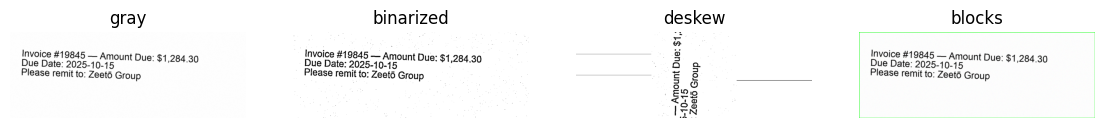

In [6]:
import matplotlib.pyplot as plt

orig_rgb = np.array(noisy_img)  # from Part 1
gray = to_gray(orig_rgb)
eq = clahe(gray)
den = denoise(eq, ksize=3)
bin_img = adaptive_binarize(den, block=31, C=10)
desk, angle = deskew(bin_img)
nolines = remove_lines(desk, scale=40)
blocks = find_text_blocks(nolines)

print(f"Deskew angle: {angle:.2f} degrees; blocks found: {len(blocks)}")

fig, axs = plt.subplots(1,4, figsize=(14,3))
axs[0].imshow(gray, cmap='gray'); axs[0].set_title('gray'); axs[0].axis('off')
axs[1].imshow(bin_img, cmap='gray'); axs[1].set_title('binarized'); axs[1].axis('off')
axs[2].imshow(desk, cmap='gray'); axs[2].set_title('deskew'); axs[2].axis('off')
axs[3].imshow(visualize_boxes(orig_rgb, blocks)); axs[3].set_title('blocks'); axs[3].axis('off')
plt.show()


### OCR the cleaned result

We’ll OCR either the **whole cleaned page** or **per block** and concatenate (often better for multi-column pages).


In [7]:
import pytesseract, easyocr

tess_config = "--oem 3 --psm 6 -l eng"

# Whole-page OCR (Tesseract)
tess_text_clean = pytesseract.image_to_string(nolines, config=tess_config)

# Block-wise OCR (Tesseract)
block_texts = []
for (x,y,w,h) in blocks:
    roi = nolines[y:y+h, x:x+w]
    txt = pytesseract.image_to_string(roi, config=tess_config)
    block_texts.append(txt.strip())
tess_block_concat = "\n".join([t for t in block_texts if t])

# EasyOCR on the cleaned page
reader = easyocr.Reader(['en'], gpu=False)
easy_results = reader.readtext(orig_rgb)              # original
easy_results_clean = reader.readtext(cv2.cvtColor(nolines, cv2.COLOR_GRAY2RGB))  # cleaned
easy_text_clean = "\n".join([r[1] for r in easy_results_clean])

print("\n[Tesseract whole-page]\n", tess_text_clean)
print("\n[Tesseract block-wise]\n", tess_block_concat)
print("\n[EasyOCR cleaned]\n", easy_text_clean)

Using CPU. Note: This module is much faster with a GPU.



[Tesseract whole-page]
 i
4 a,
‘ ny
- 1
a
nny
«a ce
ray


[Tesseract block-wise]
 i
4 a,
‘ ny
- 1
a
nny
«a ce
ray

[EasyOCR cleaned]
 



## Tiny evaluation helper

This isn’t a full OCR benchmark — just a quick way to see if you’re moving in the right direction. Replace `expected` with your known text.

In [8]:
from difflib import SequenceMatcher

def similarity(a, b):
    return SequenceMatcher(None, a, b).ratio()

expected = "Invoice #19845 — Amount Due: $1,284.30\nDue Date: 2025-10-15\nPlease remit to: Zeetō Group"

scores = {
    "tesseract_minimal": similarity(expected, tess_text),
    "tesseract_clean_page": similarity(expected, tess_text_clean),
    "tesseract_blockwise": similarity(expected, tess_block_concat),
    "easyocr_minimal": similarity(expected, easy_text),
    "easyocr_clean": similarity(expected, easy_text_clean),
}

for k, v in scores.items():
    print(f"{k:24s} -> {v:.3f}")

tesseract_minimal        -> 0.983
tesseract_clean_page     -> 0.100
tesseract_blockwise      -> 0.084
easyocr_minimal          -> 0.954
easyocr_clean            -> 0.000


> Expect **cleaned** variants to beat the minimal ones. If not, tweak `CLAHE` clip limit, adaptive threshold window (`block`), and `--psm`.

## When to pick which (rules of thumb)

- Start with **EasyOCR** if you need a single function that usually works.
- Switch to / prefer **Tesseract** if:
  - You can invest in preprocessing.
  - You need deterministic behavior with standard configs.
  - Your inputs are consistent (e.g., invoices from the same vendor).
- For tricky scans (faxed, shadowed, low DPI), the **preprocessing pipeline** is the real unlock.

## Common pitfalls & fixes

- **Low DPI (<200):** upscale (e.g., 1.5× or 2×) **after** denoise and **before** thresholding.
- **Skew:** deskew before OCR; even 2–3° helps a lot.
- **Tables/lines:** remove lines via morphology; they kill recall.
- **Bad thresholding:** try adaptive vs. Otsu; increase local window size (`block`).
- **Wrong `--psm`:** test `6`, `3`, and `11`. Results can flip depending on layout.

---

## Reproducibility checklist

- Fix your **pipeline parameters** (CLAHE clip, threshold window, morphology sizes).
- Log the **Tesseract config** and language packs used.
- Keep example images and expected text in-version.
- Add the quick **similarity** check in CI to catch regressions.


## Drop-in function: `extract_text_robust`

Here’s a compact helper you can paste into any notebook or script.

In [9]:
def extract_text_robust(img_rgb, method="tesseract", lang="eng"):
    gray = to_gray(img_rgb)
    eq = clahe(gray, clip=3.0, tile=(8,8))
    den = denoise(eq, ksize=3)
    bin_img = adaptive_binarize(den, block=31, C=10)
    desk, _ = deskew(bin_img)
    nolines = remove_lines(desk, scale=40)

    if method == "tesseract":
        cfg = f"--oem 3 --psm 6 -l {lang}"
        return pytesseract.image_to_string(nolines, config=cfg)
    elif method == "easyocr":
        rdr = easyocr.Reader([lang], gpu=False)
        return "\n".join([r[1] for r in rdr.readtext(cv2.cvtColor(nolines, cv2.COLOR_GRAY2RGB))])
    else:
        raise ValueError("method must be 'tesseract' or 'easyocr'")

## Final notes

- This post is designed to run **as-is** in a fresh environment using only synthetic data.
- Drop in real documents by replacing `orig_rgb` with `cv2.imread('path/to/scan.png')[:, :, ::-1]` (to convert BGR→RGB).
- If you discover better parameter defaults for your domain (receipts, forms, contracts), save them right in the notebook — future-you will be grateful.

**Happy OCR’ing!**